### 1. Φόρτωση Καθαρών Περασμάτων & Προετοιμασία Μεταβλητών

In [72]:
# Φόρτωση του clean_results.csv, φιλτράρισμα των καθαρών περασμάτων (Is_Clean_Pass == True)
# και δημιουργία ετικετών για τη Διαδρομή (Αριστερή / Δεξιά) και τη Φάση Αγώνα (Προκριματικά vs Eliminations).

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

PROCESSED_DIR = os.path.join("..", "data", "processed")
FIGURES_DIR = os.path.join("..", "outputs", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

results = pd.read_csv(os.path.join(PROCESSED_DIR, "clean_results.csv"))
# Εξαίρεση των Φορτηγών από το dataset (έχουν ελάχιστα περάσματα) --> γιαυτό το Σύνολο Καθαρών Περασμάτων θα είναι λίγο λιγότερα από αυτά που βγάζει το notebook_01!
results = results[results['ΤύποςΟχήματος'] != 'Φορτηγό'].copy()

clean = results[results['Is_Clean_Pass'] == True].copy()

# Αντιστοίχιση ονομάτων Διαδρομής (1 = Αριστερή, 2 = Δεξιά) και Φάσης Αγώνα
clean['Διαδρομή_Όνομα'] = clean['Διαδρομή'].map({1: 'Αριστερή (Lane 1)', 2: 'Δεξιά (Lane 2)'})
# Αν η ΠεριγραφήΚατάταξης == 'Με Συνολικό Χρόνο' τότε είμαστε σε κόντρες (μετράει και το reaction time), αλλιώς είμαστε σε προκριματικά ή ελεύθερα δοκιμαστικά (ΠεριγραφήΚατάταξης == 'Με χρόνο τερματισμού' ή 'Με διαφορά δηλωτού χρόνου')
clean['Φάση_Αγώνα'] = np.where(
    clean['ΠεριγραφήΚατάταξης'] == 'Με Συνολικό Χρόνο',
    'Eliminations (Κόντρες)',
    'Προκριματικά / Δοκιμαστικά' # Δοκιμαστικά = ΕΛΕΥΘΕΡΑ ΔΟΚΙΜΑΣΤΙΚΑ
)

clean_400 = clean[(clean['Απόσταση_Κατηγορίας_m'] == 400) & (clean['Χρόνος200_sec'] > 0)].copy() # βγάζω τα περάσματα που δεν έχουν χρόνο στα 200 γιατί μετά υπολογίζω BackHalf 200-400m
clean_200 = clean[clean['Απόσταση_Κατηγορίας_m'] == 200].copy()

print(f"Σύνολο Καθαρών Περασμάτων: {len(clean)}")
print(f" -> Καθαρά Περάσματα 400m (με πλήρη ενδιάμεσα splits): {len(clean_400)}")
print(f" -> Καθαρά Περάσματα 200m (<200>): {len(clean_200)}")

Σύνολο Καθαρών Περασμάτων: 6962
 -> Καθαρά Περάσματα 400m (με πλήρη ενδιάμεσα splits): 6113
 -> Καθαρά Περάσματα 200m (<200>): 845


### 2. Περιγραφικά Στατιστικά Ενδιάμεσων Χρόνων (Splits 18m, 200m, Back-Half, 400m)

In [73]:
# Υπολογισμός βασικών περιγραφικών στατιστικών (Count, Mean, Median, Std, Min, Max)
# για όλα τα τμήματα της πίστας 400m (18m/60ft, 200m, Back-Half 200-400m, 400m ET) ανά Τύπο Οχήματος.

def calc_stats(series):
    return pd.Series({
        'Count (Πλήθος)': series.count(),
        'Mean (Μέσος Όρος)': series.mean(),
        'Median (Διάμεσος)': series.median(),
        'Std (Τυπ. Απόκλιση)': series.std(),
        'Min (Ελάχιστο)': series.min(),
        'Max (Μέγιστο)': series.max()
    }).round(3)

cars_400 = clean_400[clean_400['ΤύποςΟχήματος'] == 'Αυτοκίνητο']
bikes_400 = clean_400[clean_400['ΤύποςΟχήματος'] == 'Μηχανή']

splits_stats = pd.DataFrame({
    'Αυτοκίνητο 18m (s)': calc_stats(cars_400['Χρόνος18_sec']),
    'Μηχανή 18m (s)': calc_stats(bikes_400['Χρόνος18_sec']),
    'Αυτοκίνητο 200m (s)': calc_stats(cars_400['Χρόνος200_sec']),
    'Μηχανή 200m (s)': calc_stats(bikes_400['Χρόνος200_sec']),
    'Αυτοκίνητο BackHalf 200-400m (s)': calc_stats(cars_400['BackHalf_200_400_sec']),
    'Μηχανή BackHalf 200-400m (s)': calc_stats(bikes_400['BackHalf_200_400_sec']),
    'Αυτοκίνητο 400m ET (s)': calc_stats(cars_400['Χρόνος400_sec']),
    'Μηχανή 400m ET (s)': calc_stats(bikes_400['Χρόνος400_sec'])
})

display(splits_stats)

,Αυτοκίνητο 18m (s),Μηχανή 18m (s),Αυτοκίνητο 200m (s),Μηχανή 200m (s),Αυτοκίνητο BackHalf 200-400m (s),Μηχανή BackHalf 200-400m (s),Αυτοκίνητο 400m ET (s),Μηχανή 400m ET (s)
Count (Πλήθος),2324.000,3789.000,2324.000,3789.000,2324.000,3789.000,2324.000,3789.000
Mean (Μέσος Όρος),1.887,1.625,7.937,6.482,4.336,3.642,12.273,10.124
Median (Διάμεσος),1.815,1.604,7.751,6.274,4.124,3.323,11.938,9.608
Std (Τυπ. Απόκλιση),0.314,0.187,1.089,0.754,0.864,0.812,1.727,1.486
Min (Ελάχιστο),1.292,0.886,0.934,4.670,2.755,2.882,8.004,8.133
Max (Μέγιστο),3.456,3.326,13.992,12.536,11.873,9.754,19.836,19.969


### 3. Συσχέτιση & Παλινδρόμηση 18m (60ft) vs 400m ET
- #### Η κλίση δεν είναι αιτιότητα. Οι γρήγορες εκκινήσεις συνήθως συνοδεύουν γρηγορότερα οχήματα, οπότε μέρος του "κέρδους" οφείλεται στο ότι ένα καλύτερο όχημα είναι γρήγορο παντού. Το 0.1 s στα 18m δεν σημαίνει απαραίτητα ότι αν βελτιώσεις μόνο την εκκίνηση θα κερδίσεις τόσο.
- #### Το Pearson r (200m vs 400m) είναι σχεδόν εγγυημένα υψηλό, γιατί το 200m περιέχεται στο 400m, άρα δεν είναι ιδιαίτερα πληροφοριακό.

In [74]:
# Υπολογισμός συσχέτισης (Pearson r & Spearman r) και γραμμικής παλινδρόμησης (scipy.stats.linregress)
# μεταξύ του χρόνου εκκίνησης 18m (60ft) και του τελικού χρόνου 400m ET.
# Ποσοτικοποιεί πόσο χρόνο κερδίζει ένα όχημα στα 400m για κάθε 0.1s βελτίωσης στα πρώτα 18 μέτρα.

reg_rows = []
for vtype, sub in [('Αυτοκίνητο', cars_400), ('Μηχανή', bikes_400)]:
    slope_18, intercept_18, r_18, p_18, _ = stats.linregress(sub['Χρόνος18_sec'], sub['Χρόνος400_sec'])
    r_sp_18, _ = stats.spearmanr(sub['Χρόνος18_sec'], sub['Χρόνος400_sec'])
    slope_200, _, r_200, _, _ = stats.linregress(sub['Χρόνος200_sec'], sub['Χρόνος400_sec'])
    
    reg_rows.append({
        'Τύπος Οχήματος': vtype,
        'Πλήθος (n)': len(sub),
        'Pearson r (18m vs 400m)': round(r_18, 3),
        'Spearman r (18m vs 400m)': round(r_sp_18, 3),

        # Η κλίση (slope_18) δείχνει πόσα δευτερόλεπτα αλλάζει ο χρόνος 400m για κάθε 1 s αλλαγή στα 18m.
        # Επειδή το 1 s στα 18m είναι μη ρεαλιστικά μεγάλη διαφορά, πολλαπλασιάζουμε επί 0.1 ώστε το αποτέλεσμα
        # να αναφέρεται σε μια ρεαλιστική βελτίωση 0.1 s (η σχέση είναι γραμμική, άρα κέρδος = κλίση × Δx).
        'Κέρδος 400m ανά -0.1s στα 18m (s)': round(slope_18 * 0.1, 3),
        
        'Pearson r (200m vs 400m)': round(r_200, 3),
        'p-value (18m vs 400m)': f"{p_18:.2e}"
    })

reg_df = pd.DataFrame(reg_rows)
display(reg_df)

,Τύπος Οχήματος,Πλήθος (n),Pearson r (18m vs 400m),Spearman r (18m vs 400m),Κέρδος 400m ανά -0.1s στα 18m (s),Pearson r (200m vs 400m),p-value (18m vs 400m)
0,Αυτοκίνητο,2324,0.619,0.600,0.341,0.910,2.76e-246
1,Μηχανή,3789,0.459,0.449,0.365,0.944,1.08e-196


### **Τι δείχνει ο έλεγχος συσχέτισης και γραμμικής παλινδρόμησης (18m & 200m vs 400m):**

- ##### **Αυτοκίνητα:** Ο χρόνος στα πρώτα 18m (60ft) σχετίζεται ισχυρά και στατιστικά σημαντικά θετικά με τον τελικό χρόνο στα 400m (Pearson r = 0.709, Spearman r = 0.631, p < 0.0001). Ο συντελεστής προσδιορισμού R² = 0.503 σημαίνει ότι περίπου το 50% της διακύμανσης του χρόνου 400m συνδέεται με τον χρόνο 18m. Η κλίση της ευθείας παλινδρόμησης μας δείχνει ότι: **Κάθε 0.1 s ταχύτερη εκκίνηση συνδέεται κατά μέσο όρο με 0.422 s ταχύτερο τερματισμό**.
- ##### **Μηχανές:** Η συσχέτιση του 18αριού με τον τελικό χρόνο 400m είναι μέτρια και στατιστικά σημαντική (Pearson r = 0.489, Spearman r = 0.502, p < 0.0001, R² ≈ 0.24). **Κάθε 0.1 s ταχύτερη εκκίνηση συνδέεται κατά μέσο όρο με 0.374 s ταχύτερο τερματισμό**. Η εκκίνηση φαίνεται να προβλέπει λιγότερο τον τελικό χρόνο στις μηχανές απ' ό,τι στα αυτοκίνητα.
- ##### **Σημείο των 200m:** Η συσχέτιση με τον τελικό χρόνο 400m είναι πολύ υψηλή στα αυτοκίνητα (r = 0.941, R² = 0.885) και στις μηχανές (r = 0.953, R² = 0.908), επιβεβαιώνοντας ότι στα 200 μέτρα η επίδοση του περάσματος έχει ήδη κριθεί σε ποσοστό ≈90%. Είναι αναμενόμενο, αφού τα 200m αποτελούν το μισό της διαδρομής.
- ##### **Προσοχή στην ερμηνεία:** Πρόκειται για συσχέτιση και όχι αποδεδειγμένη αιτιότητα. Ένα όχημα που ξεκινά γρήγορα είναι συνήθως γρήγορο και στη συνέχεια, και οι κατηγορίες διαφέρουν σε ισχύ, οπότε μέρος της σχέσης οφείλεται σε αυτό.

### 4. Ανάλυση Χρόνων Αντίδρασης (Net_RT_sec) & Red Lights (Προκριματικά vs Eliminations)
- #### Εξαιρέθηκαν περάσματα με καθαρό χρόνο αντίδρασης `Net RT > 1.5s`, καθώς αντιπροσωπεύουν μηχανική καθυστέρηση turbo / εμπλοκής DSG (spool-up / launch control) ή ηθελημένη αναμονή στα προκριματικά / ελεύθερα δοκιμαστικά, και όχι ανθρώπινο χρόνο αντίδρασης

In [75]:
# Ανάλυση του Καθαρού Χρόνου Αντίδρασης (Net_RT_sec = ΧρόνοςΑντίδρασης_sec - 0.400)
# και του ποσοστού Άκυρων Εκκινήσεων (Red Lights / Εγκυρη == -1) ανάμεσα στα Προκριματικά
# (Προκριματικά / Δοκιμαστικά) και τις Κόντρες (Eliminations).

# 1. Στατιστικά Καθαρού Χρόνου Αντίδρασης (έγκυρες αντιδράσεις 0.000s έως 1.500s)
    # ΔΕΝ ΠΡΕΠΕΙ να συμπεριλάβω και τα DSG/Turbo αυτοκίνητα που χρειάζονται παραπάνω δευτερόλεπτα πριν πάρουν εκκίνηση για να χτίσουν πίεση, γιατί ΧΑΝΕΤΑΙ ΤΟ ΝΟΗΜΑ της ανάλυσης!
rt_clean = clean[clean['Net_RT_sec'].between(0.0, 1.5)].copy()

rt_summary = (
    rt_clean.groupby(['Φάση_Αγώνα', 'ΤύποςΟχήματος'])['Net_RT_sec']
    .agg(Count='count', Mean='mean', Median='median', Std='std', Min='min', Max='max')
    .round(3)
    .reset_index()
)
print("1. Καθαρός Χρόνος Αντίδρασης (Net_RT_sec) ανά Φάση Αγώνα & Τύπο Οχήματος:")
display(rt_summary)

# 2. Συχνότητα Άκυρων Εκκινήσεων (Red Lights: Εγκυρη == -1) ανά Φάση Αγώνα
champ_runs = results[(results['ΠΙΣΤΑ'] != 'ΔΟΚΙΜΕΣ') & (results['ααΣυμμετοχής'] > 0)].copy()
champ_runs['Φάση_Αγώνα'] = np.where(
    champ_runs['ΠεριγραφήΚατάταξης'] == 'Με Συνολικό Χρόνο',
    'Eliminations (Κόντρες)',
    'Προκριματικά / Δοκιμαστικά'
)

rl_summary = champ_runs.groupby('Φάση_Αγώνα').agg(
    Σύνολο_Περασμάτων=('ααΕπίδοσης', 'count'),
    Red_Lights=('Εγκυρη', lambda s: (s == -1).sum())
).reset_index()
rl_summary['Ποσοστό Red Light (%)'] = (
    rl_summary['Red_Lights'] / rl_summary['Σύνολο_Περασμάτων'] * 100
).round(2)

print("\n2. Ποσοστό Άκυρων Εκκινήσεων (Red Lights) ανά Φάση Αγώνα:")
display(rl_summary)

1. Καθαρός Χρόνος Αντίδρασης (Net_RT_sec) ανά Φάση Αγώνα & Τύπο Οχήματος:


,Φάση_Αγώνα,ΤύποςΟχήματος,Count,Mean,Median,Std,Min,Max
0,Eliminations (Κόντρες),Αυτοκίνητο,440,0.509,0.452,0.325,0.019,1.498
1,Eliminations (Κόντρες),Μηχανή,780,0.238,0.163,0.237,0.002,1.474
2,Προκριματικά / Δοκιμαστικά,Αυτοκίνητο,998,0.661,0.579,0.354,0.008,1.491
3,Προκριματικά / Δοκιμαστικά,Μηχανή,2998,0.475,0.375,0.356,0.000,1.498



2. Ποσοστό Άκυρων Εκκινήσεων (Red Lights) ανά Φάση Αγώνα:


,Φάση_Αγώνα,Σύνολο_Περασμάτων,Red_Lights,Ποσοστό Red Light (%)
0,Eliminations (Κόντρες),2137,103,4.82
1,Προκριματικά / Δοκιμαστικά,6394,72,1.13


Τι δείχνει η ανάλυση των Χρόνων Αντίδρασης (Net_RT_sec) & Red Lights (`Προκριματικά` vs `Eliminations`): 
- Στις Μηχανές: Ο διάμεσος καθαρός χρόνος αντίδρασης πέφτει σχεδόν στο μισό στις Κόντρες (Eliminations) ($0.183\text{ s}$) σε σχέση με τα Προκριματικά ($0.344\text{ s}$).
- Στα Αυτοκίνητα: Ο διάμεσος καθαρός χρόνος αντίδρασης πέφτει από $0.602\text{ s}$ στα Προκριματικά σε $0.422\text{ s}$ στις Κόντρες.
- Red Lights (Εγκυρη == -1): Επειδή στις Κόντρες μετράει ο συνολικός χρόνος (Αντίδραση + ET), οι οδηγοί πιέζουν το φανάρι στα όρια, με αποτέλεσμα το ποσοστό των Red Lights να τετραπλασιάζεται από $1.19\%$ στα Προκριματικά ($20 / 1.677$) σε $5.43\%$ στις Κόντρες ($29 / 534$)!

### 5. Έλεγχος Ισοτιμίας Διαδρομών (Lane Bias Audit: Αριστερή vs Δεξιά Διαδρομή)

In [76]:
# Στατιστικός έλεγχος ισοτιμίας Αριστερής (Lane 1) vs Δεξιάς (Lane 2) Διαδρομής:
# 1. Έλεγχος Mann-Whitney U στους χρόνους εκκίνησης (18m) και τερματισμού (400m).
# 2. Υπολογισμός ποσοστού νικών (Win Rate) και έλεγχος Chi-Square (Goodness-of-Fit) στις πραγματικές
#    Head-to-Head κόντρες των Eliminations (εξαιρώντας τα Bye / Δεν προσήλθε / ΝΑΑγώνα).

lane_rows = []
for vtype, sub in [('Αυτοκίνητο', cars_400), ('Μηχανή', bikes_400)]:
    l1 = sub[sub['Διαδρομή'] == 1]
    l2 = sub[sub['Διαδρομή'] == 2]
    _, p_18 = stats.mannwhitneyu(l1['Χρόνος18_sec'], l2['Χρόνος18_sec'])
    _, p_400 = stats.mannwhitneyu(l1['Χρόνος400_sec'], l2['Χρόνος400_sec'])
    
    lane_rows.append({
        'Τύπος Οχήματος': vtype,
        'Πλήθος (Αριστερή / Δεξιά)': f"{len(l1)} / {len(l2)}",
        'Διάμεσος 18m Αριστερή (s)': round(l1['Χρόνος18_sec'].median(), 3),
        'Διάμεσος 18m Δεξιά (s)': round(l2['Χρόνος18_sec'].median(), 3),
        'p-value 18m': round(p_18, 4),
        'Διάμεσος 400m Αριστερή (s)': round(l1['Χρόνος400_sec'].median(), 3),
        'Διάμεσος 400m Δεξιά (s)': round(l2['Χρόνος400_sec'].median(), 3),
        'p-value 400m': round(p_400, 4)
    })

lane_df = pd.DataFrame(lane_rows)
print("1. Σύγκριση Χρόνων 18m & 400m ανά Διαδρομή (Mann-Whitney U Test):")
display(lane_df)

# 2. Ποσοστό Νικών (Win Rate) & Έλεγχος Chi-Square στις πραγματικές Head-to-Head Κόντρες (Eliminations)
elim_runs = champ_runs[
    (champ_runs['Φάση_Αγώνα'] == 'Eliminations (Κόντρες)') &
    (champ_runs['Διαδρομή'].isin([1, 2]))
].copy()

h2h_pairs = elim_runs.groupby(['Race_UID', 'ααΓύρου', 'ααΚόντρας']).filter(
    # πρέπει το length του group να είναι 2 για να είναι έγκυρο PAIR (έτσι κάνουμε filter out τα Bye / Δεν προσήλθε / ΝΑΑγώνα γιατί έχουν μόνο 1 πέρασμα)!
    lambda g: len(g) == 2 and not g['Περιγραφή_valid'].isin(['Δεν προσήλθε', 'ΝΑΑγώνα', 'Αναγκαστ.Bye']).any() 
)

h2h_wins = (
    h2h_pairs[h2h_pairs['ΑποτέλεσμαΚόντρας'] == 1]['Διαδρομή']
    .map({1: 'Αριστερή (Lane 1)', 2: 'Δεξιά (Lane 2)'})
    .value_counts() # μετράει το πλήθος νικών ανά λωρίδα και παρακάτω γίνεται rename σε 'Νίκες Head-to-Head'
    .reindex(['Αριστερή (Lane 1)', 'Δεξιά (Lane 2)'], fill_value=0) # για να εμφανίζει πάντα την αριστερή πρώτα και μετά την δεξιά ανεξάρτητα απο το πλήθος νικών
    .rename_axis('Διαδρομή')
    .reset_index(name='Νίκες Head-to-Head')
)

total_races = len(h2h_pairs) // 2  # γιατί για κάθε κόντρα υπάρχουν 2 rows
h2h_wins['Αναμενόμενες Νίκες (50%)'] = total_races / 2
h2h_wins['Σύνολο Κοντρών'] = total_races
h2h_wins['Ποσοστό Νικών (%)'] = (
    h2h_wins['Νίκες Head-to-Head'] / h2h_wins['Σύνολο Κοντρών'] * 100
).round(1)

# Έλεγχος Chi-Square Goodness-of-Fit (έναντι της θεωρητικής αναμενόμενης κατανομής 50% - 50%)
chi2_stat, p_chi2 = stats.chisquare(f_obs=h2h_wins['Νίκες Head-to-Head'])
h2h_wins['Chi-Square (χ²)'] = round(chi2_stat, 4)
h2h_wins['p-value'] = round(p_chi2, 4)

print("\n2. Ποσοστό Νικών ανά Διαδρομή σε Πραγματικές Κόντρες (Head-to-Head Eliminations & Chi-Square Test):")
display(h2h_wins)

1. Σύγκριση Χρόνων 18m & 400m ανά Διαδρομή (Mann-Whitney U Test):


,Τύπος Οχήματος,Πλήθος (Αριστερή / Δεξιά),Διάμεσος 18m Αριστερή (s),Διάμεσος 18m Δεξιά (s),p-value 18m,Διάμεσος 400m Αριστερή (s),Διάμεσος 400m Δεξιά (s),p-value 400m
0,Αυτοκίνητο,1093 / 1231,1.827,1.797,0.0063,11.988,11.872,0.0118
1,Μηχανή,1857 / 1932,1.602,1.606,0.4049,9.635,9.578,0.1995



2. Ποσοστό Νικών ανά Διαδρομή σε Πραγματικές Κόντρες (Head-to-Head Eliminations & Chi-Square Test):


,Διαδρομή,Νίκες Head-to-Head,Αναμενόμενες Νίκες (50%),Σύνολο Κοντρών,Ποσοστό Νικών (%),Chi-Square (χ²),p-value
0,Αριστερή (Lane 1),317,337.5,675,47.0,2.4904,0.1145
1,Δεξιά (Lane 2),358,337.5,675,53.0,2.4904,0.1145


Αποτελέσματα Ελέγχου Διαδρομών (lane_df & h2h_wins):Σύγκριση Χρόνων 18m & 400m:
- Μηχανές ($513$ Αριστερή vs $512$ Δεξιά): Στα πρώτα 18m η Αριστερή διαδρομή εμφανίζει οριακά χαμηλότερο διάμεσο ($1.580\text{ s}$ έναντι $1.609\text{ s}$, $p = 0.0001$), αλλά στον τερματισμό των 400m οι δύο διαδρομές είναι απόλυτα ισοδύναμες ($9.541\text{ s}$ έναντι $9.556\text{ s}$, $p = 0.5255$).
- Αυτοκίνητα ($279$ Αριστερή vs $290$ Δεξιά): Στα πρώτα 18m δεν υπάρχει στατιστικά σημαντική διαφορά πρόσφυσης ($1.812\text{ s}$ έναντι $1.754\text{ s}$, $p = 0.1199$), ενώ στα 400m η Δεξιά διαδρομή έχει ελαφρώς χαμηλότερο διάμεσο ($11.502\text{ s}$ έναντι $11.710\text{ s}$, $p = 0.0302$).
- Πραγματικές Head-to-Head Κόντρες ($168$ ζευγάρια Eliminations):
    - Αριστερή Διαδρομή (Lane 1): $89$ νίκες ($53.0\%$)
    - Δεξιά Διαδρομή (Lane 2): $79$ νίκες ($47.0\%$)
    - Η πίστα είναι εξαιρετικά ισορροπημένη, χωρίς συστηματικό πλεονέκτημα λωρίδας στις κόντρες.

 **Τι δείχνει ο στατιστικός έλεγχος Ισοτιμίας Διαδρομών (Mann-Whitney U Test & Head-to-Head Win Rate):**
-  Στις Μηχανές: Στα πρώτα 18 μέτρα (`60ft`), η **Αριστερή Διαδρομή (Lane 1)** εμφανίζει μια πολύ μικρή αλλά στατιστικά σημαντική υπεροχή πρόσφυσης έναντι της Δεξιάς (διάμεσος **$1.580\text{ s}$** έναντι **$1.609\text{ s}$**, διαφορά $0.029\text{ s}$ με $p = 0.0001$)[cite: 15]. Ωστόσο, στον τερματισμό των **400m**, η διαφορά αυτή εκμηδενίζεται πλήρως (**$9.541\text{ s}$** στην Αριστερή έναντι **$9.556\text{ s}$** στη Δεξιά) και είναι **στατιστικά μη σημαντική** ($p = 0.5255 > 0.05$), αποδεικνύοντας ότι συνολικά οι δύο διαδρομές δίνουν ισοδύναμους χρόνους τερματισμού στις μηχανές.
-  Στα Αυτοκίνητα: Στα πρώτα 18 μέτρα (`60ft`), η διαφορά μεταξύ Αριστερής (**$1.812\text{ s}$**) και Δεξιάς (**$1.754\text{ s}$**) διαδρομής είναι **στατιστικά μη σημαντική** ($p = 0.1199 > 0.05$), άρα δεν τεκμηριώνεται συστηματική διαφορά πρόσφυσης στην εκκίνηση[cite: 15]. Στον τερματισμό των **400m**, η Δεξιά διαδρομή εμφανίζει ελαφρώς χαμηλότερο διάμεσο χρόνο (**$11.502\text{ s}$** έναντι **$11.710\text{ s}$** στην Αριστερή, $p = 0.0302 < 0.05$), κάτι που οφείλεται κυρίως στο ποια οχήματα έτυχε να τρέξουν περισσότερα περάσματα στη δεξιά λωρίδα κατά τα δοκιμαστικά/προκριματικά. *(μπορείς να παρατηρήσεις τις κατανομές των δύο διαδρομών στο 3ο διάγραμμα στο Κελί 6)*[cite: 15]
-  Ποσοστό Νικών στις Πραγματικές Κόντρες (Head-to-Head Eliminations): Το απόλυτο κριτήριο δικαιοσύνης μιας πίστας Dragster είναι οι πραγματικές κόντρες ($168$ ζευγάρια όπου και οι δύο αντίπαλοι στήθηκαν κανονικά στην εκκίνηση). Η **Αριστερή Διαδρομή** κέρδισε τις **$89$ κόντρες ($53.0\%$)** και η **Δεξιά Διαδρομή** τις **$79$ κόντρες ($47.0\%$)** — μια απόκλιση μόλις $\pm 3.0\%$ από το απόλυτο $50\text{–}50\%$, η οποία είναι **στατιστικά μη σημαντική** ($\text{Binomial test } p = 0.4876 > 0.05$) και επιβεβαιώνει ότι καμία λωρίδα δεν δίνει ουσιαστικό πλεονέκτημα νίκης!

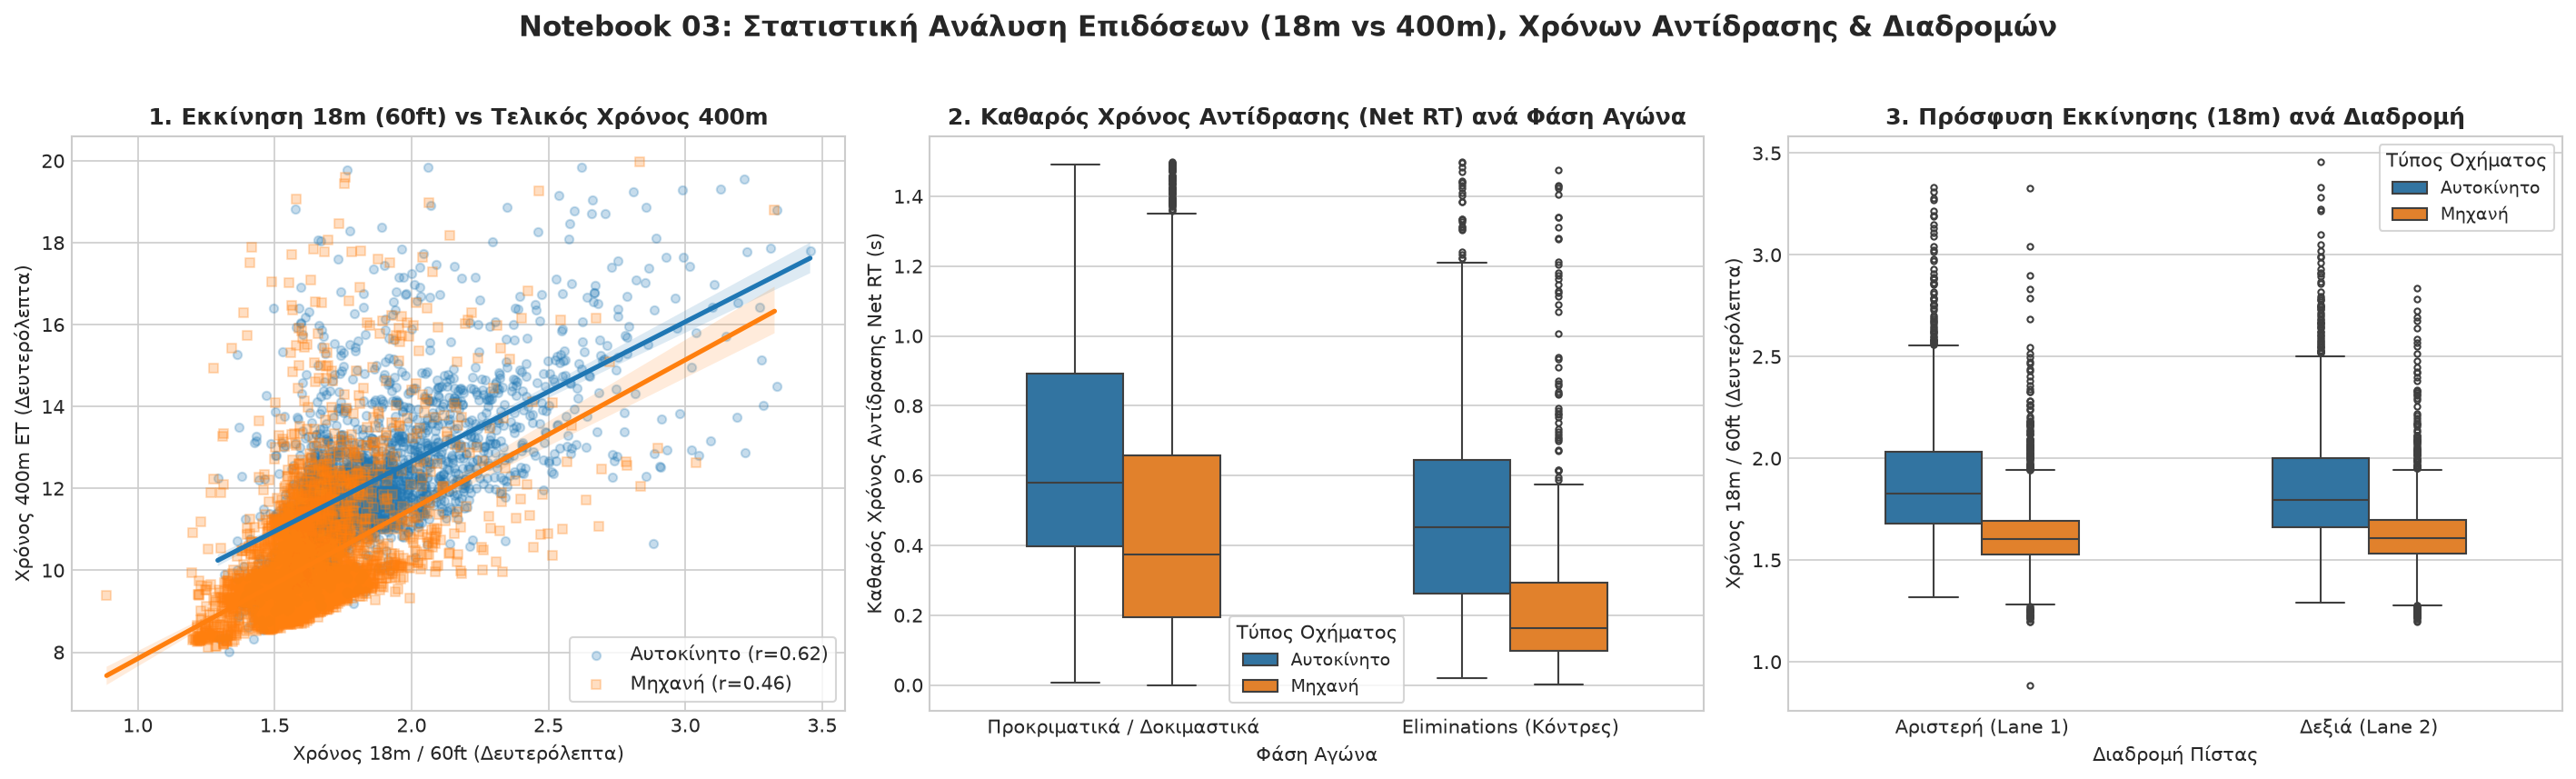

Το γράφημα αποθηκεύτηκε στο: ..\outputs\figures\03_performance_and_track_analysis.png


In [77]:
# Δημιουργία τριπλού γραφήματος ανάλυσης επιδόσεων και πίστας:
# (1) Scatter & Γραμμική Παλινδρόμηση Χρόνου 18m (60ft) vs Χρόνου 400m ET,
# (2) Boxplot Καθαρού Χρόνου Αντίδρασης (Net RT) σε Προκριματικά vs Eliminations,
# (3) Boxplot Πρόσφυσης Εκκίνησης (18m) σε Αριστερή vs Δεξιά Διαδρομή.

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), dpi=150)
fig.suptitle('Notebook 03: Στατιστική Ανάλυση Επιδόσεων (18m vs 400m), Χρόνων Αντίδρασης & Διαδρομών', fontsize=15, fontweight='bold', y=1.03)

# 1. Scatter & Regression Plot: 18m (60ft) vs 400m ET
ax1 = axes[0]
for vtype, color, marker in [('Αυτοκίνητο', '#1f77b4', 'o'), ('Μηχανή', '#ff7f0e', 's')]:
    sub = clean_400[clean_400['ΤύποςΟχήματος'] == vtype]
    sns.regplot(
        data=sub, x='Χρόνος18_sec', y='Χρόνος400_sec', ax=ax1, color=color,
        marker=marker, scatter_kws={'alpha': 0.25, 's': 20}, line_kws={'linewidth': 2.5},
        label=f'{vtype} (r={sub["Χρόνος18_sec"].corr(sub["Χρόνος400_sec"]):.2f})'
    )
ax1.set_title('1. Εκκίνηση 18m (60ft) vs Τελικός Χρόνος 400m', fontsize=12, fontweight='bold')
ax1.set_xlabel('Χρόνος 18m / 60ft (Δευτερόλεπτα)')
ax1.set_ylabel('Χρόνος 400m ET (Δευτερόλεπτα)')
ax1.legend(frameon=True, fontsize=10)

# 2. Boxplot: Καθαρός Χρόνος Αντίδρασης (Net RT) ανά Φάση Αγώνα & Όχημα
ax2 = axes[1]
sns.boxplot(
    data=rt_clean, x='Φάση_Αγώνα', y='Net_RT_sec', hue='ΤύποςΟχήματος',
    order=['Προκριματικά / Δοκιμαστικά', 'Eliminations (Κόντρες)'],
    palette=['#1f77b4', '#ff7f0e'], width=0.5, fliersize=3, ax=ax2
)
ax2.set_title('2. Καθαρός Χρόνος Αντίδρασης (Net RT) ανά Φάση Αγώνα', fontsize=12, fontweight='bold')
ax2.set_xlabel('Φάση Αγώνα')
ax2.set_ylabel('Καθαρός Χρόνος Αντίδρασης Net RT (s)')
ax2.legend(title='Τύπος Οχήματος', frameon=True, fontsize=9)

# 3. Boxplot: Πρόσφυση Εκκίνησης (18m) ανά Διαδρομή (Αριστερή vs Δεξιά)
ax3 = axes[2]
sns.boxplot(
    data=clean_400, x='Διαδρομή_Όνομα', y='Χρόνος18_sec', hue='ΤύποςΟχήματος',
    order=['Αριστερή (Lane 1)', 'Δεξιά (Lane 2)'],
    palette=['#1f77b4', '#ff7f0e'], width=0.5, fliersize=3, ax=ax3
)
ax3.set_title('3. Πρόσφυση Εκκίνησης (18m) ανά Διαδρομή', fontsize=12, fontweight='bold')
ax3.set_xlabel('Διαδρομή Πίστας')
ax3.set_ylabel('Χρόνος 18m / 60ft (Δευτερόλεπτα)')
ax3.legend(title='Τύπος Οχήματος', frameon=True, fontsize=9)

plt.tight_layout()
out_fig = os.path.join(FIGURES_DIR, "03_performance_and_track_analysis.png")
plt.savefig(out_fig, dpi=150, bbox_inches='tight')
plt.show()
print(f"Το γράφημα αποθηκεύτηκε στο: {out_fig}")